# 01 · Audio: what a microphone gives you

Ten seconds of voice, and what the computer actually holds.

- 16,000 numbers a second, mono, `float32`
- Each number: air pressure at one instant, between -1 and +1

## 1.0 · What sampling does to a wave

Two waves, both measured 16,000 times a second. Each dot is one number.

- 1,000 Hz: 16 dots per cycle, traced exactly
- 12,000 Hz: under 2 dots per cycle, a false 4,000 Hz wave appears

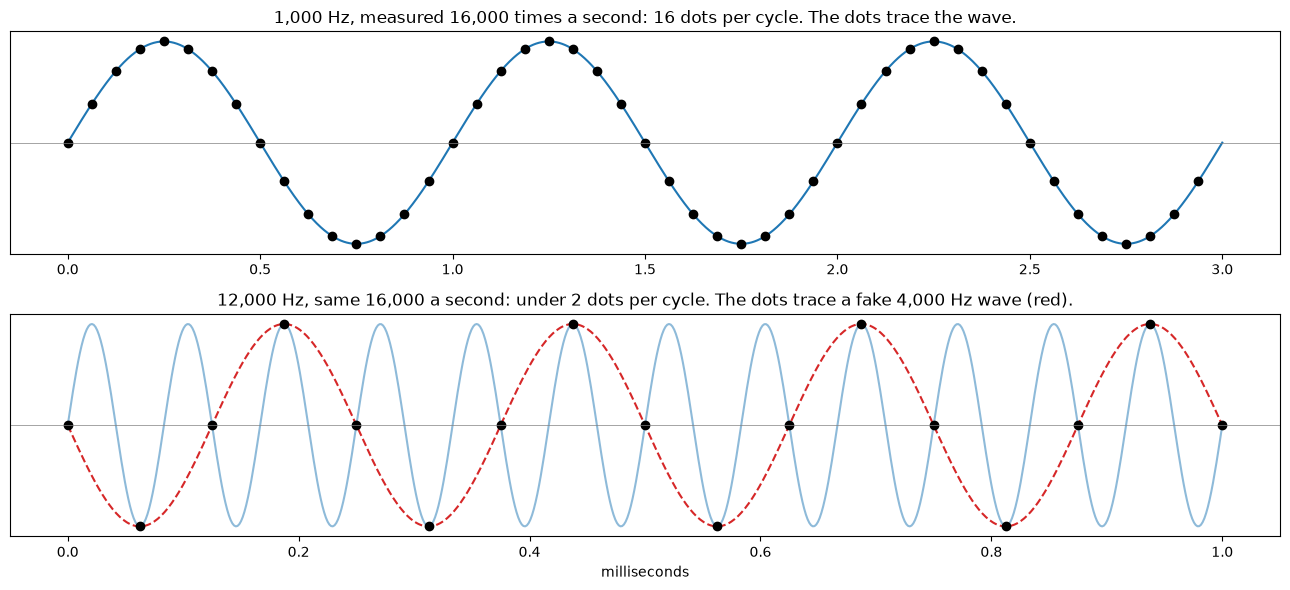

In [5]:
import numpy as np
import matplotlib.pyplot as plt

SR = 16_000                                   # samples per second
fine = np.linspace(0, 0.003, 2000)            # "continuous" time, for drawing the real wave
dots = np.arange(0, 0.003, 1 / SR)            # the moments we actually measure

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6))

# 1,000 Hz: 16 measurements per cycle. The dots trace the wave.
ax1.plot(fine * 1000, np.sin(2 * np.pi * 1000 * fine), color="tab:blue")
ax1.plot(dots * 1000, np.sin(2 * np.pi * 1000 * dots), "o", color="black")
ax1.set_title("1,000 Hz, measured 16,000 times a second: 16 dots per cycle. The dots trace the wave.")

# 12,000 Hz: under 2 measurements per cycle. The dots trace a wave that was never there.
d1 = dots[dots <= 0.001]; f1 = fine[fine <= 0.001]
ax2.plot(f1 * 1000, np.sin(2 * np.pi * 12000 * f1), color="tab:blue", alpha=0.5)
ax2.plot(f1 * 1000, -np.sin(2 * np.pi * 4000 * f1), "--", color="tab:red")
ax2.plot(d1 * 1000, np.sin(2 * np.pi * 12000 * d1), "o", color="black")
ax2.set_title("12,000 Hz, same 16,000 a second: under 2 dots per cycle. The dots trace a fake 4,000 Hz wave (red).")
ax2.set_xlabel("milliseconds")

for ax in (ax1, ax2):
    ax.set_yticks([]); ax.axhline(0, color="gray", lw=0.5)
plt.tight_layout()
plt.show()

## 1.1 · Find your microphone

In [6]:
import sounddevice as sd
import numpy as np

SAMPLE_RATE = 16_000  # Hz. Non-negotiable: every ASR model expects this.
CHANNELS = 1          # mono

for idx, dev in enumerate(sd.query_devices()):
    if dev["max_input_channels"] > 0:
        marker = "  <-- default" if idx == sd.default.device[0] else ""
        print(f"[{idx}] {dev['name']}")
        print(f"     channels={dev['max_input_channels']}  "
              f"native_rate={int(dev['default_samplerate'])} Hz{marker}")

[0] iPhone  Microphone
     channels=1  native_rate=48000 Hz
[1] MacBook Air Microphone
     channels=1  native_rate=48000 Hz  <-- default


`native_rate` is usually 48,000 Hz. It gets resampled to 16,000.

## 1.2 · Record ten seconds

Say a sentence with a filler in it, e.g. *"So I'm building, um, a voice dictation app."*

In [7]:
DURATION = 10.0  # seconds

print("Recording in 1 second... get ready")
sd.sleep(1000)
print("SPEAK NOW")

audio = sd.rec(
    frames=int(DURATION * SAMPLE_RATE),
    samplerate=SAMPLE_RATE,
    channels=CHANNELS,
    dtype="float32",
)
sd.wait()  # block until the recording finishes

# sd.rec always returns 2D: (frames, channels). We are mono, so channels=1 and
# the shape is (160000, 1). Every model downstream wants a flat 1D array of
# samples, so drop the useless second axis now rather than debugging it later.
audio = audio.flatten()  # (160000, 1) -> (160000,)
print(f"Done. shape={audio.shape}")

Recording in 1 second... get ready
SPEAK NOW
Done. shape=(160000,)


## 1.3 · What you captured

In [8]:
print(f"type          : {type(audio).__name__}")
print(f"shape         : {audio.shape}   <- {DURATION} sec x {SAMPLE_RATE} samples/sec")
print(f"dtype         : {audio.dtype}")
print(f"memory        : {audio.nbytes / 1024:.0f} KB")
print()
print(f"min amplitude : {audio.min():+.4f}")
print(f"max amplitude : {audio.max():+.4f}")

rms = float(np.sqrt(np.mean(audio**2)))
verdict = ("TOO QUIET, accuracy will suffer" if rms < 0.01 else
           "a bit quiet" if rms < 0.02 else
           "healthy" if rms < 0.30 else
           "very loud, watch for clipping")
print(f"RMS (loudness): {rms:.4f}   <- {verdict}")
print(f"clipped samples: {int(np.sum(np.abs(audio) >= 0.999))}  (should be 0)")

# macOS system input volume. Wispr Flow's own support post names a low setting
# here as a leading cause of bad transcription IN PRODUCTION. One line to check.
import subprocess

raw = subprocess.run(
    ["osascript", "-e", "input volume of (get volume settings)"],
    capture_output=True, text=True, timeout=5,
).stdout.strip()

if raw == "missing value":
    print(f"input volume  : not reported by this mic "
          f"({sd.query_devices(sd.default.device[0])['name']})")
elif raw.isdigit():
    vol = int(raw)
    hint = "  <-- LOW. System Settings > Sound > Input, drag it up" if vol < 75 else ""
    print(f"input volume  : {vol}/100{hint}")
else:
    print(f"input volume  : could not read ({raw!r})")

print()
print("first 10 raw numbers:")
print(audio[:10])

type          : ndarray
shape         : (160000,)   <- 10.0 sec x 16000 samples/sec
dtype         : float32
memory        : 625 KB

min amplitude : -0.1820
max amplitude : +0.1553
RMS (loudness): 0.0162   <- a bit quiet
clipped samples: 0  (should be 0)
input volume  : 72/100  <-- LOW. System Settings > Sound > Input, drag it up

first 10 raw numbers:
[-0.00067848 -0.00096606 -0.0006976  -0.00051228 -0.0002978  -0.00019342
 -0.00015511 -0.00036398 -0.00051997 -0.00091731]


- **RMS**: overall loudness. 0.02 to 0.30 is healthy
- **First numbers**: near zero, before you started talking

## 1.4 · See it

Top: the whole recording. Bottom: 20 ms, every number a dot.

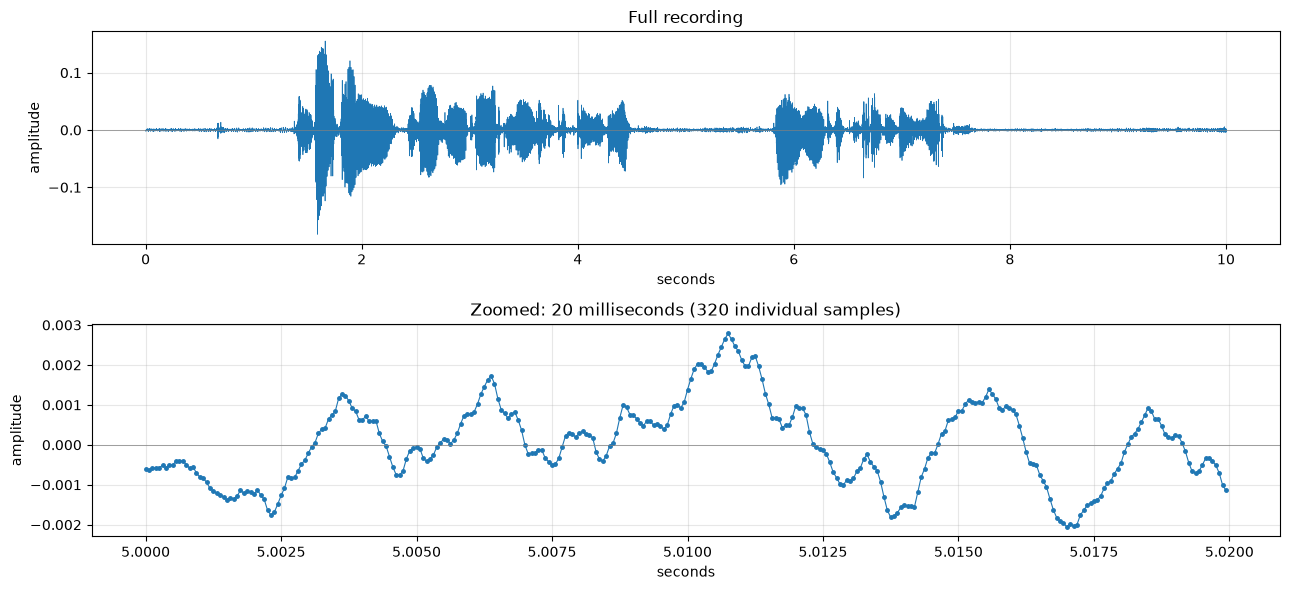

In [9]:
import matplotlib.pyplot as plt

time_axis = np.arange(len(audio)) / SAMPLE_RATE  # sample index -> seconds

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6))

ax1.plot(time_axis, audio, linewidth=0.5)
ax1.set_title("Full recording")
ax1.set_xlabel("seconds")
ax1.set_ylabel("amplitude")
ax1.axhline(0, color="gray", linewidth=0.5)
ax1.grid(alpha=0.3)

# Zoom into 20 milliseconds from the middle, where you were definitely speaking.
mid = len(audio) // 2
window = int(0.02 * SAMPLE_RATE)  # 20 ms = 320 samples
ax2.plot(time_axis[mid:mid + window], audio[mid:mid + window],
         marker="o", markersize=2.5, linewidth=0.8)
ax2.set_title(f"Zoomed: 20 milliseconds ({window} individual samples)")
ax2.set_xlabel("seconds")
ax2.set_ylabel("amplitude")
ax2.axhline(0, color="gray", linewidth=0.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Fat = speech, flat = silence
- Frequency is on neither axis

## 1.45 · Seeing frequency

Spectrogram: time across, frequency up, colour = energy.

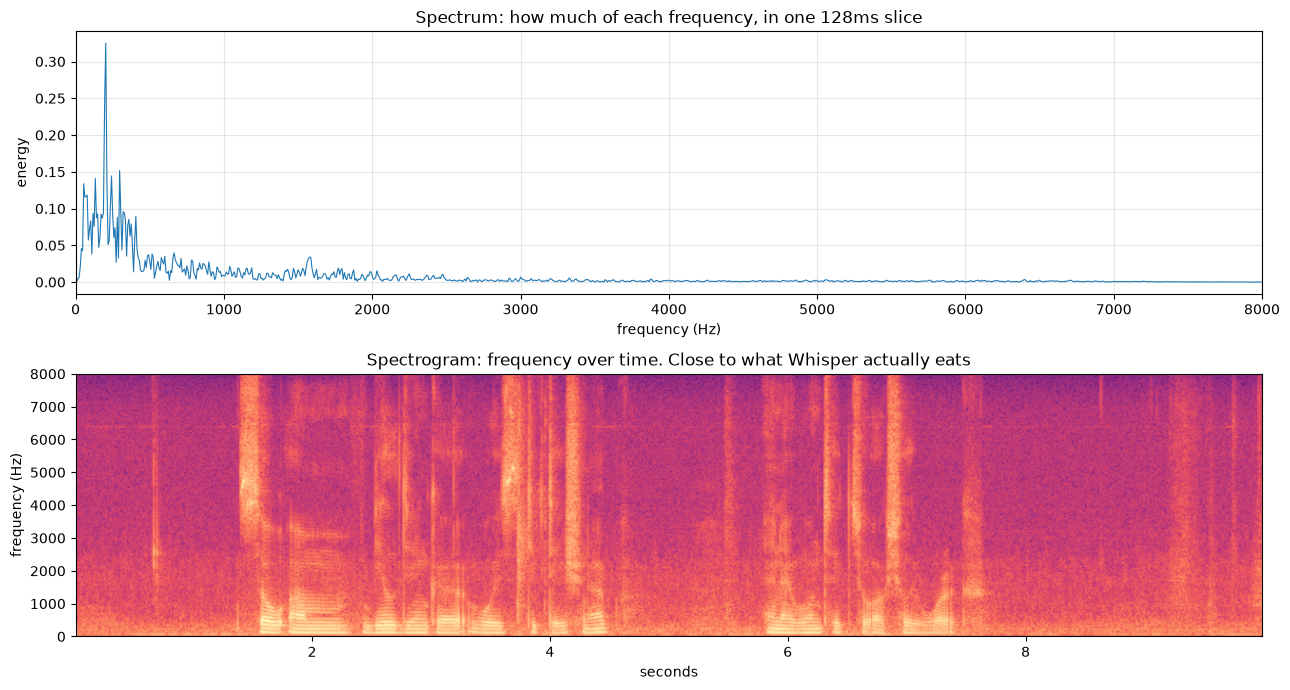

Strongest frequency in the voice range: 203 Hz
(typical adult male 85-180 Hz, adult female 165-255 Hz)
If this looks wrong, the slice probably landed on silence or a consonant.


In [10]:
# --- Spectrum: one 128ms slice, all frequencies at once ---------------------
mid = len(audio) // 2
n_fft = 2048
slice_ = audio[mid:mid + n_fft] * np.hanning(n_fft)  # taper edges to avoid artifacts

spectrum = np.abs(np.fft.rfft(slice_))               # energy at each frequency
freqs = np.fft.rfftfreq(n_fft, d=1 / SAMPLE_RATE)    # what frequency each bin means

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7))

ax1.plot(freqs, spectrum, linewidth=0.8)
ax1.set_title("Spectrum: how much of each frequency, in one 128ms slice")
ax1.set_xlabel("frequency (Hz)")
ax1.set_ylabel("energy")
ax1.set_xlim(0, 8000)   # 8000 Hz is our ceiling: half of 16000, per Nyquist
ax1.grid(alpha=0.3)

# --- Spectrogram: frequency over time --------------------------------------
ax2.specgram(audio, NFFT=512, Fs=SAMPLE_RATE, noverlap=384, cmap="magma")
ax2.set_title("Spectrogram: frequency over time. Close to what Whisper actually eats")
ax2.set_xlabel("seconds")
ax2.set_ylabel("frequency (Hz)")

plt.tight_layout()
plt.show()

# Find the loudest low-frequency peak: that is your vocal pitch.
voice_band = (freqs > 70) & (freqs < 400)
pitch = freqs[voice_band][np.argmax(spectrum[voice_band])]
print(f"Strongest frequency in the voice range: {pitch:.0f} Hz")
print("(typical adult male 85-180 Hz, adult female 165-255 Hz)")
print("If this looks wrong, the slice probably landed on silence or a consonant.")

## 1.5 · Play it back (optional)

In [1]:
from IPython.display import Audio, display

peak = float(np.max(np.abs(audio)))

print("1. As recorded. True loudness, byte for byte what the model will eat:")
display(Audio(audio, rate=SAMPLE_RATE, normalize=False))

NameError: name 'np' is not defined